# Previsão de Produtividade Municipal da Soja no RS — Modelagem, Avaliação e Explicabilidade (N2)

**Integrantes:** Isabelle Franco (RA 10425395) · Gustavo Rodrigues (RA 10403091) · Pedro Henrique (RA 10388298) · Lorenzo Tadeo (RA 10420067)
**Orientador:** Prof. Dr. Ivan Carlos Alcântara de Oliveira — Inteligência Artificial, 7º CC, Universidade Presbiteriana Mackenzie (FCI)

**Síntese do conteúdo deste arquivo:** dá continuidade à análise exploratória da N1 (`analise_exploratoria.ipynb`). Reconstrói o painel município×safra com melhorias de preparação (estação INMET *válida* mais próxima, atributos do período crítico dez–fev, balanço hídrico P−ETo de Hargreaves, janela pré-safra do ONI), integra a **adubação fosfatada** (dose de P₂O₅ recomendada pela CQFS-RS/SC e equivalentes em MAP, SS, ST e DAP), ajusta hiperparâmetros em safras de **validação** (2010–2015), compara Regressão Linear, Random Forest e Gradient Boosting contra três linhas de base em validação temporal *walk-forward* nas safras de **teste** (2016–2025), analisa erros (por safra, fase do ENOS, região e distância da estação), avalia o uso como **alerta de quebra de safra**, mede a contribuição de cada grupo de atributos (ablação) e explica o melhor modelo com **SHAP**. Ao final, demonstra o artefato de previsão (`src/prever_safra.py`).

| Data       | Autor             | Descrição |
|------------|-------------------|-----------|
| 2026-11-19 | Isabelle Franco   | Criação do notebook da N2; reconstrução do painel com estação válida mais próxima e atributos dez–fev |
| 2026-11-19 | Gustavo Rodrigues | Divisão validação/teste, ajuste de hiperparâmetros e walk-forward com três baselines |
| 2026-11-19 | Pedro Henrique    | Integração da adubação fosfatada e estudo de ablação por grupo de atributos |
| 2026-11-19 | Lorenzo Tadeo     | Análise de erros, alerta de quebra de safra, SHAP e demonstração do artefato; exportação das figuras 4–9 |

## 1. Configuração

O código reutilizável fica em `src/soja_pipeline.py` (mesmo cabeçalho/histórico); este notebook orquestra as etapas, mostra as evidências e exporta figuras e tabelas:

- figuras do artigo → `artigo/latex/figuras/fig4…fig9`;
- tabelas de resultados → `resultados/`.

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, str(Path("..", "src").resolve()))
import soja_pipeline as sp

FIGDIR = Path("../artigo/latex/figuras"); FIGDIR.mkdir(parents=True, exist_ok=True)
RESDIR = Path("../resultados"); RESDIR.mkdir(exist_ok=True)

# Paleta (validada para daltonismo): baselines em cinza, modelos nos 3 primeiros slots
COR = {"Baseline: média histórica": "#898781", "Baseline: safra anterior": "#b5b3ab",
       "Baseline: média 5 safras": "#52514e", "Regressão Linear": "#2a78d6",
       "Random Forest": "#eb6834", "Gradient Boosting": "#1baf7a"}
ESTILO = {"Baseline: média histórica": ":", "Baseline: safra anterior": "--",
          "Baseline: média 5 safras": "-."}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e1e0d9",
                     "grid.linewidth": 0.6, "figure.facecolor": "white", "savefig.dpi": 160})
pd.set_option("display.width", 200, "display.max_columns", 30)

VALIDACAO = list(range(2010, 2016))   # escolha de hiperparâmetros e de configuração
TESTE = list(range(2016, 2026))       # usado UMA vez, só para o relatório final
print("Validação:", VALIDACAO, "| Teste:", TESTE)

Validação: [2010, 2011, 2012, 2013, 2014, 2015] | Teste: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


## 2. Arquitetura da solução

Fluxo completo, das fontes públicas ao artefato. A figura é exportada para o artigo (Figura 4).

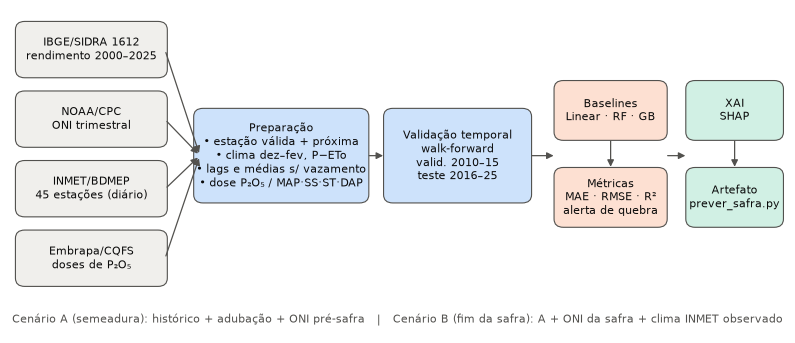

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.2)); ax.set_axis_off(); ax.set_xlim(0, 10); ax.set_ylim(0, 4.2)
def caixa(x, y, w, h, txt, cor="#cde2fb"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.12",
                                fc=cor, ec="#52514e", lw=0.8))
    ax.text(x + w/2, y + h/2, txt, ha="center", va="center", fontsize=7.8, color="#0b0b0b")
def seta(x1, y1, x2, y2):
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=0.9))
ax.set_ylim(-0.45, 4.2)
fontes = ["IBGE/SIDRA 1612\nrendimento 2000–2025", "NOAA/CPC\nONI trimestral",
          "INMET/BDMEP\n45 estações (diário)", "Embrapa/CQFS\ndoses de P₂O₅"]
for i, f in enumerate(fontes):
    caixa(0.1, 3.25 - i*1.0, 1.9, 0.75, f, "#f0efec")
    seta(2.0, 3.62 - i*1.0, 2.45, 2.1)
caixa(2.4, 1.45, 2.2, 1.3, "Preparação\n• estação válida + próxima\n• clima dez–fev, P−ETo\n• lags e médias s/ vazamento\n• dose P₂O₅ / MAP·SS·ST·DAP")
seta(4.6, 2.1, 4.85, 2.1)
caixa(4.85, 1.45, 1.85, 1.3, "Validação temporal\nwalk-forward\nvalid. 2010–15\nteste 2016–25")
seta(6.7, 2.1, 7.05, 2.1)
caixa(7.05, 2.35, 1.4, 0.8, "Baselines\nLinear · RF · GB", "#fde0d2")
caixa(7.05, 1.1, 1.4, 0.8, "Métricas\nMAE · RMSE · R²\nalerta de quebra", "#fde0d2")
seta(7.75, 2.35, 7.75, 1.9)
seta(8.45, 2.1, 8.75, 2.1)
caixa(8.75, 2.35, 1.2, 0.8, "XAI\nSHAP", "#d1f0e4")
caixa(8.75, 1.1, 1.2, 0.8, "Artefato\nprever_safra.py", "#d1f0e4")
seta(9.35, 2.35, 9.35, 1.9)
ax.text(5, -0.3, "Cenário A (semeadura): histórico + adubação + ONI pré-safra   |   "
        "Cenário B (fim da safra): A + ONI da safra + clima INMET observado",
        ha="center", fontsize=8.2, color="#52514e")
fig.savefig(FIGDIR / "fig4_arquitetura.png", bbox_inches="tight"); plt.show()

## 3. Reconstrução do painel (melhorias de preparação em relação à N1)

Na N1 cada município usava sempre a estação mais próxima; quando ela estava em *pane*, o clima ficava ausente (~45% do painel sem precipitação). Agora:

1. **Estação válida mais próxima** (até 100 km): se a mais próxima falhou naquela safra, usa-se a seguinte, registrando a distância efetiva (`dist_estacao_km`).
2. **Período crítico dez–fev** (floração/enchimento de grãos): chuva, **balanço hídrico P − ETo** (ETo de Hargreaves-Samani, que só exige temperatura e latitude), Tmax média, dias com Tmax ≥ 32 °C, maior sequência de dias secos, chuva mensal nov–mar e **anomalia da chuva** frente à normal da própria estação calculada só com safras anteriores.
3. **ONI pré-safra** (ASO+SON, conhecido na semeadura) além do ONI da safra (OND–JFM, igual à N1).
4. **Histórico sem vazamento**: lags 1 e 2, média expandida, média móvel de 5 safras, máximo histórico, nº de safras e log da área da safra anterior — tudo calculado só com safras anteriores.

In [3]:
t0 = time.time()
df = sp.construir_painel()
print(f"tempo: {time.time()-t0:.1f}s")
df.to_csv("../dataset/processed/painel_modelagem_n2.csv", index=False)

cobertura = pd.DataFrame({
    "N1 (estação mais próxima)": pd.read_csv("../dataset/processed/painel_municipio_safra.csv")
        .query("rendimento_kg_ha.notna()")["precipitacao_total_safra_mm"].notna().mean(),
    "N2 (estação válida mais próxima)": df.loc[df.rendimento_kg_ha.notna(), "precip_dez_fev_mm"].notna().mean(),
}, index=["% pares com rendimento que têm clima"]).T * 100
print(cobertura.round(1))
print("\nDistância efetiva até a estação usada (km):")
print(df["dist_estacao_km"].describe().round(1).to_string())

Painel de modelagem: (12922, 42)
Pares com rendimento: 10540
Pares com clima dez-fev: 10186
tempo: 4.1s


                                  % pares com rendimento que têm clima
N1 (estação mais próxima)                                         55.7
N2 (estação válida mais próxima)                                  79.2

Distância efetiva até a estação usada (km):
count    10186.0
mean        38.8
std         20.8
min          0.3
25%         24.6
50%         36.7
75%         51.1
max        100.0


In [4]:
cols = ["precip_dez_fev_mm", "balanco_hidrico_dez_fev_mm", "anomalia_precip_dez_fev_pct",
        "tmax_dez_fev_c", "dias_calor_dez_fev", "max_dias_secos_dez_fev"]
resumo_safra = df.groupby("ano_safra")[["rendimento_kg_ha"] + cols].mean().round(1)
resumo_safra.loc[2003:]

,rendimento_kg_ha,precip_dez_fev_mm,balanco_hidrico_dez_fev_mm,anomalia_precip_dez_fev_pct,tmax_dez_fev_c,dias_calor_dez_fev,max_dias_secos_dez_fev
ano_safra,,,,,,,
2003,2396.9,167.5,NaN,NaN,29.7,26.6,15.1
2004,1354.2,476.1,3.9,NaN,29.1,15.1,20.3
2005,662.3,118.1,-369.8,-2.4,30.5,30.6,12.0
2006,1873.3,327.2,-170.0,50.4,29.9,21.4,12.3
2007,2391.3,383.8,-90.3,33.3,29.7,21.9,9.4
2008,1994.9,315.0,-161.4,3.7,29.0,16.8,11.4
2009,2065.5,392.2,-64.9,20.6,28.1,14.3,9.4
2010,2521.4,572.1,126.6,48.8,28.8,15.8,8.1
2011,2799.8,498.8,50.4,28.0,28.5,12.7,8.6


As safras de quebra (2005, 2012, 2020, 2022, 2023) aparecem com balanço hídrico dez–fev fortemente negativo. Note que **2022 e 2023** combinam déficit com Tmax média dez–fev de 31–32 °C — valores **acima de qualquer safra do período de treino** —, o que antecipa uma dificuldade: os modelos de árvores não extrapolam além da faixa observada.

## 4. Adubação fosfatada (pendência da N1)

Não existe base pública do fósforo efetivamente aplicado por município e safra. Adotou-se uma **hipótese explícita e documentada**, a partir das tabelas 2.3/2.4 da Embrapa/CQFS-RS/SC:

- solo com teor de P **"Médio"**, **2º cultivo** após a correção (situação típica de lavouras de grãos consolidadas);
- dose = dose-base da Tabela 2.4 (para 2 t/ha) **+ 15 kg/ha de P₂O₅ por t/ha** de rendimento esperado acima de 2 t/ha (o mesmo para K₂O, +25 kg/ha);
- rendimento esperado = **média histórica do município antes da safra** (sem vazamento);
- quantidade equivalente de produto comercial: MAP (52% P₂O₅), Superfosfato Simples (18%), Superfosfato Triplo (41%) e DAP (46%).

In [5]:
print(pd.read_csv("../dataset/raw/embrapa_tabela_2.4_recomendacao_p2o5_k2o_soja.csv").to_string(index=False))
print()
print(df[sp.ATR_ADUBACAO].describe().round(1).T[["mean", "min", "50%", "max"]])
print("\nCorrelação de Spearman entre dose de P2O5 e média histórica:",
      round(df[["dose_p2o5_recomendada", "rend_media_hist"]].corr(method="spearman").iloc[0, 1], 3))

interpretacao_teor_p_k  p2o5_kg_ha_1o_cultivo  p2o5_kg_ha_2o_cultivo  k2o_kg_ha_1o_cultivo  k2o_kg_ha_2o_cultivo
           Muito baixo                    110                     70                   125                    85
                 Baixo                     70                     50                    85                    65
                 Medio                     60                     30                    75                    45
                  Alto                     30                     30                    45                    45
            Muito alto                      0                     30                     0                    45

                        mean    min    50%    max
dose_p2o5_recomendada   32.9   30.0   30.5   57.0
dose_k2o_recomendada    49.8   45.0   45.8   90.0
kg_map_ha_equiv         63.3   57.7   58.6  109.6
kg_ss_ha_equiv         182.8  166.7  169.3  316.7
kg_st_ha_equiv          80.2   73.2   74.3  139.0
kg_dap_ha_equiv      

**Observação crítica:** como a classe de solo é única e o rendimento esperado vem do próprio histórico, a dose é uma função **monótona** da média histórica (Spearman ≈ 1). Para modelos de árvores, uma transformação monótona de um atributo já existente não acrescenta informação. A ablação (Seção 9) mede isso empiricamente. Trocar a classe (ex.: "Alto") apenas desloca a dose por uma constante, sem alterar o resultado das árvores — a limitação é **dos dados públicos disponíveis**, não do método.

## 5. Base de modelagem e protocolo de avaliação

- Alvo: `rendimento_kg_ha` (regressão supervisionada).
- Linhas com alvo observado, ≥ 3 safras anteriores com rendimento e clima observado no período crítico (em 2003–2006 menos da metade dos municípios tem estação operando; imputar essas safras, que incluem a seca de 2005, ensinaria ao modelo que uma quebra ocorreu com clima "normal").
- **Walk-forward com janela expandida:** para cada safra *t*, treina com todas as safras < *t* e prevê *t*. Nunca há divisão aleatória.
- **Validação (2010–2015)** para escolher hiperparâmetros; **teste (2016–2025)** usado uma única vez.
- Três baselines: média histórica expandida, safra anterior e média móvel das 5 últimas safras.

In [6]:
base = sp.base_modelavel(df)
print("Base modelável:", base.shape, "| safras", base.ano_safra.min(), "–", base.ano_safra.max(),
      "| municípios", base.codigo_ibge_municipio.nunique())
print("Linhas de validação:", base.ano_safra.isin(VALIDACAO).sum(), "| de teste:", base.ano_safra.isin(TESTE).sum())
for c, a in sp.CENARIOS.items():
    print(f"{c}: {len(a)} atributos")

Base modelável: (7951, 42) | safras 2003 – 2025 | municípios 440
Linhas de validação: 2348 | de teste: 4158
A_pre_safra: 16 atributos
B_fim_safra: 31 atributos


## 6. Ajuste de hiperparâmetros (somente validação)

Grade pequena de propósito: com poucas safras independentes, uma busca extensa sobreajustaria a própria seleção. Critério: menor MAE no walk-forward 2010–2015, cenário B.

In [7]:
t0 = time.time()
PARAMS, grade = sp.ajustar_hiperparametros(base, sp.CENARIOS["B_fim_safra"], VALIDACAO)
print(f"tempo: {time.time()-t0:.0f}s")
grade.to_csv(RESDIR / "ajuste_hiperparametros_validacao.csv", index=False)
(RESDIR / "hiperparametros.json").write_text(json.dumps(PARAMS, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(PARAMS, indent=1, ensure_ascii=False))
grade.round(3)

tempo: 22s
{
 "Regressão Linear": {
  "alpha": 100.0
 },
 "Random Forest": {
  "min_samples_leaf": 5,
  "max_features": 0.6
 },
 "Gradient Boosting": {
  "learning_rate": 0.03,
  "max_leaf_nodes": 31,
  "min_samples_leaf": 20
 }
}


,modelo,params,MAE,RMSE,R2,MAPE_%
0,Regressão Linear,{'alpha': 0.1},493.256,642.243,0.130,29.141
1,Regressão Linear,{'alpha': 1.0},490.927,639.900,0.137,29.077
2,Regressão Linear,{'alpha': 10.0},481.502,630.996,0.161,28.777
3,Regressão Linear,{'alpha': 100.0},465.652,615.420,0.202,27.975
4,Random Forest,"{'min_samples_leaf': 5, 'max_features': 0.33}",406.481,516.285,0.438,22.944
5,Random Forest,"{'min_samples_leaf': 5, 'max_features': 0.6}",399.616,511.121,0.449,22.481
6,Random Forest,"{'min_samples_leaf': 20, 'max_features': 0.33}",419.016,526.586,0.415,23.152
7,Random Forest,"{'min_samples_leaf': 20, 'max_features': 0.6}",400.434,506.680,0.459,21.953
8,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",419.413,531.330,0.405,22.690
9,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 31, ...",406.006,515.742,0.439,21.795


In [8]:
val = {c: sp.walk_forward(base, a, VALIDACAO, params=PARAMS) for c, a in sp.CENARIOS.items()}
tab_val = pd.concat([sp.tabela_metricas(p).assign(cenario=c) for c, p in val.items()])
print(tab_val.pivot(index="modelo", columns="cenario", values="MAE").round(0))
MELHOR = (tab_val.query("cenario == 'B_fim_safra' and not modelo.str.startswith('Baseline')")
          .sort_values("MAE").iloc[0]["modelo"])
print("\nModelo selecionado na VALIDAÇÃO (cenário B):", MELHOR)

cenario                    A_pre_safra  B_fim_safra
modelo                                             
Baseline: média 5 safras         626.0        626.0
Baseline: média histórica        770.0        770.0
Baseline: safra anterior         665.0        665.0
Gradient Boosting                785.0        406.0
Random Forest                    737.0        400.0
Regressão Linear                 593.0        466.0

Modelo selecionado na VALIDAÇÃO (cenário B): Random Forest


### 6.1 Diagnóstico guiado por XAI: o atributo `ano_safra`

Numa primeira rodada, o SHAP (Seção 10) mostrou `ano_safra` entre os atributos mais importantes, com valores **recentes empurrando a previsão para baixo**. A explicação: árvores não extrapolam no tempo — a safra prevista cai sempre na "última folha" do treino e herda o regime das safras mais recentes (ex.: após a seca de 2020, a previsão de 2021 era puxada para baixo). O atributo foi retirado; a decisão foi tomada **na validação** (não no teste): a remoção reduz o MAE da Regressão Linear e do Random Forest e é neutra para o Gradient Boosting.

In [9]:
com_ano = sp.CENARIOS["B_fim_safra"] + ["ano_safra"]
p_com = sp.walk_forward(base, com_ano, VALIDACAO, params=PARAMS)
p_sem = val["B_fim_safra"]
diag = pd.DataFrame({"com ano_safra": sp.tabela_metricas(p_com).set_index("modelo").MAE,
                     "sem ano_safra (adotado)": sp.tabela_metricas(p_sem).set_index("modelo").MAE}).loc[sp.MODELOS]
diag.to_csv(RESDIR / "diagnostico_ano_safra_validacao.csv")
diag.round(0)

,com ano_safra,sem ano_safra (adotado)
modelo,,
Regressão Linear,482.0,466.0
Random Forest,413.0,400.0
Gradient Boosting,406.0,406.0


## 7. Resultados no conjunto de teste (2016–2025)

In [10]:
t0 = time.time()
teste, modelos_teste = {}, {}
for c, a in sp.CENARIOS.items():
    teste[c], modelos_teste[c] = sp.walk_forward(base, a, TESTE, params=PARAMS, guardar_modelos=True)
print(f"tempo: {time.time()-t0:.0f}s")
tab = pd.concat([sp.tabela_metricas(p).assign(cenario=c) for c, p in teste.items()])
tab.to_csv(RESDIR / "metricas_teste_2016_2025.csv", index=False)
melhor_base_mae = tab.query("modelo.str.startswith('Baseline')").MAE.min()
tab["ganho_MAE_vs_melhor_baseline_%"] = (1 - tab.MAE / melhor_base_mae) * 100
tab.round(3)

tempo: 39s


,modelo,MAE,RMSE,R2,MAPE_%,n,cenario,ganho_MAE_vs_melhor_baseline_%
0,Baseline: média histórica,836.822,953.847,-0.184,40.344,4158,A_pre_safra,-20.283
1,Baseline: safra anterior,828.945,1113.509,-0.614,48.459,4158,A_pre_safra,-19.150
2,Baseline: média 5 safras,695.714,895.498,-0.044,43.288,4158,A_pre_safra,0.000
3,Regressão Linear,728.590,965.254,-0.213,48.135,4158,A_pre_safra,-4.725
4,Random Forest,789.512,1019.040,-0.352,46.465,4158,A_pre_safra,-13.482
5,Gradient Boosting,782.003,997.530,-0.295,44.461,4158,A_pre_safra,-12.403
0,Baseline: média histórica,836.822,953.847,-0.184,40.344,4158,B_fim_safra,-20.283
1,Baseline: safra anterior,828.945,1113.509,-0.614,48.459,4158,B_fim_safra,-19.150
2,Baseline: média 5 safras,695.714,895.498,-0.044,43.288,4158,B_fim_safra,0.000
3,Regressão Linear,611.646,783.779,0.200,37.030,4158,B_fim_safra,12.084


In [11]:
pB = teste["B_fim_safra"]
pB.to_csv(RESDIR / "previsoes_teste_cenarioB.csv", index=False)
por_ano = sp.tabela_metricas(pB, por="ano_safra")
mae_ano = por_ano.pivot(index="ano_safra", columns="modelo", values="MAE")[sp.NOMES_PREVISORES]
mae_ano.to_csv(RESDIR / "mae_por_safra_cenarioB.csv")
print(mae_ano.round(0))
# Comparação contra a baseline fixada a priori (a mais forte no agregado).
# Comparar com "a melhor baseline de cada ano" seria um oráculo escolhido a posteriori.
print("\nSafras em que cada modelo vence a baseline média 5 safras:")
for m in sp.MODELOS:
    print(f"  {m}: {(mae_ano[m] < mae_ano['Baseline: média 5 safras']).sum()} de {len(mae_ano)}")

modelo     Baseline: média histórica  Baseline: safra anterior  Baseline: média 5 safras  Regressão Linear  Random Forest  Gradient Boosting
ano_safra                                                                                                                                   
2016                           938.0                     285.0                     569.0             659.0          329.0              344.0
2017                          1183.0                     399.0                     773.0             489.0          516.0              527.0
2018                           943.0                     318.0                     348.0             354.0          325.0              337.0
2019                           944.0                     295.0                     295.0             308.0          252.0              253.0
2020                           645.0                    1239.0                    1152.0            1073.0         1207.0             1200.0
2021         

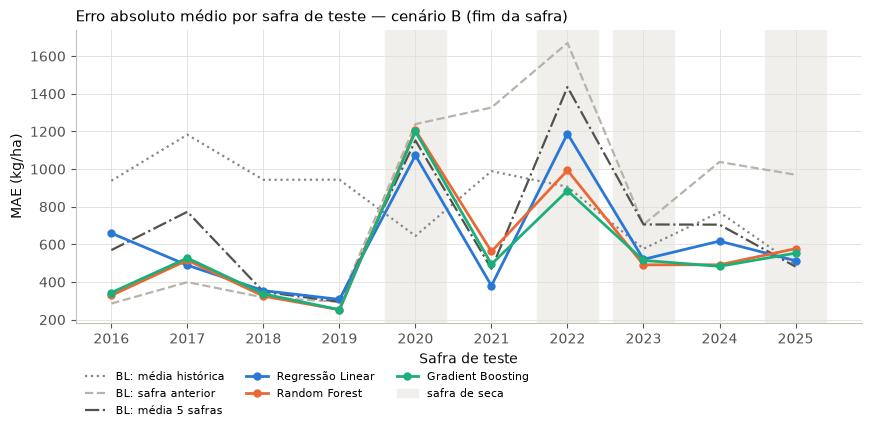

In [12]:
fig, ax = plt.subplots(figsize=(8.6, 4.2), constrained_layout=True)
for nome in sp.NOMES_PREVISORES:
    base_ = nome.startswith("Baseline")
    ax.plot(mae_ano.index, mae_ano[nome], color=COR[nome], lw=1.6 if base_ else 2,
            ls=ESTILO.get(nome, "-"), marker=None if base_ else "o", ms=5, label=nome.replace("Baseline: ", "BL: "))
for i, a in enumerate([2020, 2022, 2023, 2025]):
    ax.axvspan(a - .4, a + .4, color="#f0efec", zorder=0, label="safra de seca" if i == 0 else None)
ax.set_xlabel("Safra de teste"); ax.set_ylabel("MAE (kg/ha)")
ax.set_title("Erro absoluto médio por safra de teste — cenário B (fim da safra)", loc="left", fontsize=10.5)
ax.set_xticks(mae_ano.index)
ax.legend(ncol=3, fontsize=7.8, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.13))
fig.savefig(FIGDIR / "fig5_mae_por_safra.png", bbox_inches="tight"); plt.show()

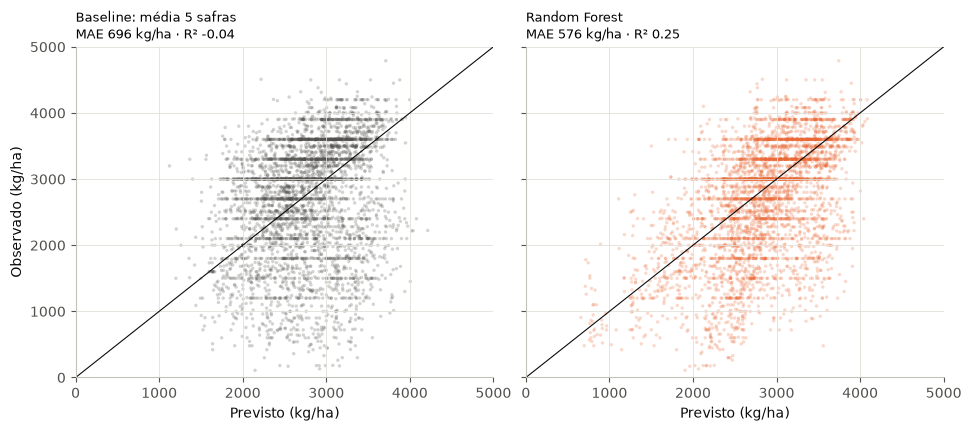

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.2), constrained_layout=True, sharey=True)
for ax, nome in zip(axs, ["Baseline: média 5 safras", MELHOR]):
    ax.scatter(pB[nome], pB.rendimento_kg_ha, s=6, alpha=.25, color=COR[nome], edgecolor="none")
    ax.plot([0, 5000], [0, 5000], color="#0b0b0b", lw=.8)
    m = sp.metricas(pB.rendimento_kg_ha, pB[nome])
    ax.set_title(f"{nome}\nMAE {m['MAE']:.0f} kg/ha · R² {m['R2']:.2f}", loc="left", fontsize=9.5)
    ax.set_xlabel("Previsto (kg/ha)"); ax.set_xlim(0, 5000); ax.set_ylim(0, 5000)
axs[0].set_ylabel("Observado (kg/ha)")
fig.savefig(FIGDIR / "fig6_observado_previsto.png", bbox_inches="tight"); plt.show()

A nuvem do modelo se alinha melhor à diagonal, mas há uma faixa de previsões entre 2.000 e 3.500 kg/ha para pares que de fato renderam < 1.500 kg/ha: são as secas severas, cuja **magnitude** é subestimada (regressão à média).

## 8. Análise de erros

In [14]:
pB["regiao"] = pd.cut(pB.latitude, [-34, -30.5, -28.8, -27], labels=["Sul", "Centro", "Norte"])
pB["faixa_dist_km"] = pd.cut(pB.dist_estacao_km, [-1, 20, 40, 100], labels=["≤20", "20–40", "40–100"])
pB["porte"] = pd.qcut(pB.area_plantada_ha, 3, labels=["pequeno", "médio", "grande"])
saidas = {}
for g in ["fase_enos", "regiao", "faixa_dist_km", "porte"]:
    t = sp.tabela_metricas(pB, por=g)
    saidas[g] = t.pivot(index=g, columns="modelo", values="MAE")[["Baseline: média 5 safras"] + sp.MODELOS]
    saidas[g]["n"] = t.groupby(g, observed=True).n.first()
    print(f"\nMAE por {g}:"); print(saidas[g].round(0))
pd.concat(saidas, names=["recorte"]).to_csv(RESDIR / "mae_por_recorte_cenarioB.csv")


MAE por fase_enos:
modelo     Baseline: média 5 safras  Regressão Linear  Random Forest  Gradient Boosting     n
fase_enos                                                                                    
El Niño                       682.0             665.0          572.0              572.0  1661
La Niña                       743.0             613.0          594.0              559.0  1674
Neutro                        626.0             501.0          546.0              540.0   823

MAE por regiao:
modelo  Baseline: média 5 safras  Regressão Linear  Random Forest  Gradient Boosting     n
regiao                                                                                    
Centro                     633.0             580.0          567.0              559.0  1478
Norte                      748.0             625.0          577.0              555.0  2301
Sul                        624.0             655.0          604.0              599.0   379

MAE por faixa_dist_km:
modelo        

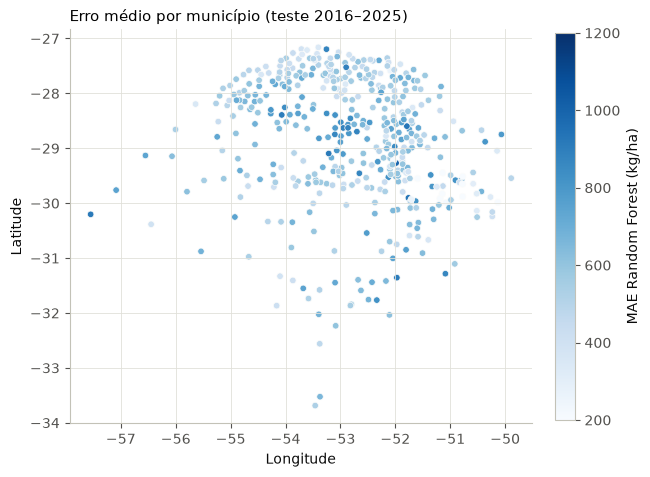

 codigo_ibge_municipio                municipio   lat   lon   mae  n
               4304697             Capitão - RS -29.0 -52.0 989.0  1
               4308805      General Câmara - RS -30.0 -52.0 930.0 10
               4314001               Paraí - RS -29.0 -52.0 928.0 10
               4301875     Barra do Quaraí - RS -30.0 -58.0 916.0  8
               4316451      Salto do Jacuí - RS -29.0 -53.0 915.0 10
               4305871      Coronel Barros - RS -28.0 -54.0 906.0 10
               4318804 São Lourenço do Sul - RS -31.0 -52.0 906.0 10
               4321956     Trindade do Sul - RS -28.0 -53.0 890.0 10


In [15]:
erro_mun = (pB.assign(err=(pB[MELHOR] - pB.rendimento_kg_ha).abs())
              .groupby(["codigo_ibge_municipio", "municipio"])
              .agg(lat=("latitude", "first"), lon=("longitude", "first"), mae=("err", "mean"), n=("err", "size"))
              .reset_index())
fig, ax = plt.subplots(figsize=(6.4, 5), constrained_layout=True)
sc = ax.scatter(erro_mun.lon, erro_mun.lat, c=erro_mun.mae, cmap="Blues", s=22, vmin=200, vmax=1200,
                edgecolor="#fcfcfb", linewidth=0.5)
fig.colorbar(sc, ax=ax, label=f"MAE {MELHOR} (kg/ha)", shrink=.8)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")
ax.set_title("Erro médio por município (teste 2016–2025)", loc="left", fontsize=10.5)
fig.savefig(FIGDIR / "fig9_erro_espacial.png", bbox_inches="tight"); plt.show()
print(erro_mun.sort_values("mae", ascending=False).head(8).round(0).to_string(index=False))

### 8.1 Uso aplicado: alerta de quebra de safra

Quebra observada = rendimento < 80% da média histórica do município. Alerta = previsão < 80% da média histórica. A tabela mostra a matriz de confusão e as métricas; a curva varia o limiar do alerta para mostrar o compromisso precisão × revocação.

In [16]:
alerta = sp.avaliar_alerta_quebra(pB)
alerta.to_csv(RESDIR / "alerta_quebra_cenarioB.csv", index=False)
print("Taxa de quebra observada no teste:", round((pB.rendimento_kg_ha < .8 * pB["Baseline: média histórica"]).mean() * 100, 1), "%")
alerta.round(3)

Taxa de quebra observada no teste: 19.6 %


,modelo,VP,FP,FN,VN,precisao,revocacao,F1,acuracia
0,Baseline: safra anterior,148,524,666,2820,0.220,0.182,0.199,0.714
1,Baseline: média 5 safras,9,7,805,3337,0.562,0.011,0.022,0.805
2,Regressão Linear,59,23,755,3321,0.720,0.072,0.132,0.813
3,Random Forest,142,86,672,3258,0.623,0.174,0.273,0.818
4,Gradient Boosting,126,87,688,3257,0.592,0.155,0.245,0.814


In [17]:
real = pB.rendimento_kg_ha < .8 * pB["Baseline: média histórica"]
linhas = []
for k in np.arange(0.80, 1.06, 0.025):
    for nome in ["Baseline: média 5 safras", MELHOR]:
        a = pB[nome] < k * pB["Baseline: média histórica"]
        tp = (a & real).sum(); prec = tp / max(a.sum(), 1); rec = tp / real.sum()
        linhas.append({"limiar": round(k, 3), "modelo": nome, "precisao": prec, "revocacao": rec,
                       "F1": 2 * prec * rec / (prec + rec) if prec + rec else 0})
curva = pd.DataFrame(linhas)
curva.to_csv(RESDIR / "curva_limiar_alerta.csv", index=False)
print(curva.pivot(index="limiar", columns="modelo", values=["precisao", "revocacao", "F1"]).round(2))

                       precisao                              revocacao                                     F1              
modelo Baseline: média 5 safras Random Forest Baseline: média 5 safras Random Forest Baseline: média 5 safras Random Forest
limiar                                                                                                                     
0.800                      0.56          0.62                     0.01          0.17                     0.02          0.27
0.825                      0.60          0.60                     0.01          0.18                     0.03          0.28
0.850                      0.50          0.57                     0.02          0.19                     0.04          0.29
0.875                      0.51          0.56                     0.03          0.21                     0.06          0.30
0.900                      0.39          0.54                     0.05          0.22                     0.09          0.31
0.925   

Com o limiar estrito de 80% o modelo é **conservador** (alta precisão, baixa revocação): quando alerta, costuma acertar, mas deixa passar a maior parte das quebras. Elevar o limiar do alerta aumenta a revocação ao custo de mais falsos alarmes — escolha que, num uso real, cabe ao gestor conforme o custo de cada tipo de erro (ver discussão ética no artigo).

## 9. Ablação: quanto cada grupo de atributos contribui?

Mesmo protocolo de teste, adicionando os grupos um a um (modelos de árvores com os hiperparâmetros escolhidos na validação).

In [18]:
H, AD, OP, OS, CL = sp.ATR_HIST, sp.ATR_ADUBACAO, sp.ATR_ONI_PRE, sp.ATR_ONI_SAFRA, sp.ATR_CLIMA
grupos = {
    "Histórico": H,
    "+ Adubação": H + AD,
    "+ ONI pré-safra (= cenário A)": H + AD + OP,
    "+ ONI da safra": H + AD + OP + OS,
    "+ Clima INMET (= cenário B)": H + AD + OP + OS + CL,
    "Cenário B sem adubação": H + OP + OS + CL,
}
linhas = []
for g, a in grupos.items():
    p = sp.walk_forward(base, a, TESTE, params=PARAMS, modelos=["Random Forest", "Gradient Boosting"])
    for m in ["Random Forest", "Gradient Boosting"]:
        linhas.append({"grupo": g, "modelo": m, **sp.metricas(p.rendimento_kg_ha, p[m])})
abl = pd.DataFrame(linhas); abl.to_csv(RESDIR / "ablacao_atributos.csv", index=False)
print(abl.pivot(index="grupo", columns="modelo", values="MAE").loc[list(grupos)].round(0))

modelo                         Gradient Boosting  Random Forest
grupo                                                          
Histórico                                  768.0          761.0
+ Adubação                                 768.0          763.0
+ ONI pré-safra (= cenário A)              782.0          790.0
+ ONI da safra                             765.0          740.0
+ Clima INMET (= cenário B)                561.0          576.0
Cenário B sem adubação                     561.0          582.0


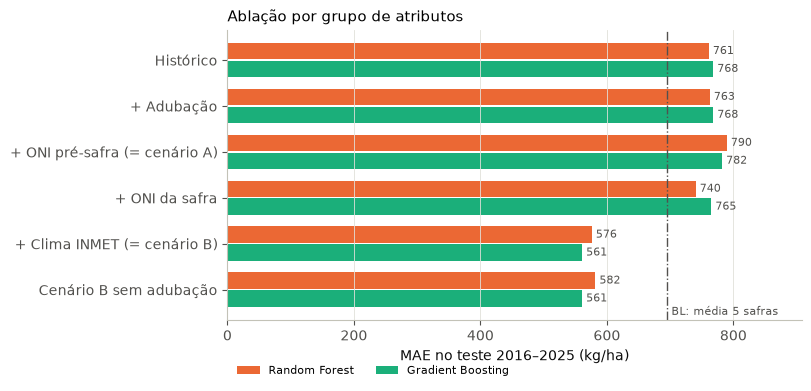

In [19]:
piv = abl.pivot(index="grupo", columns="modelo", values="MAE").loc[list(grupos)]
fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
y = np.arange(len(piv)); h = .36
for i, m in enumerate(["Random Forest", "Gradient Boosting"]):
    b = ax.barh(y + (i - .5) * (h + .03), piv[m], height=h, color=COR[m], label=m)
    ax.bar_label(b, fmt="%.0f", padding=3, fontsize=8, color="#52514e")
ref = tab.query("cenario=='B_fim_safra' and modelo=='Baseline: média 5 safras'").MAE.iloc[0]
ax.axvline(ref, color="#52514e", ls="-.", lw=1); ax.text(ref, len(piv) - .45, " BL: média 5 safras", fontsize=8, color="#52514e")
ax.set_yticks(y, piv.index); ax.invert_yaxis(); ax.set_xlabel("MAE no teste 2016–2025 (kg/ha)")
ax.set_xlim(0, max(piv.max().max(), ref) * 1.15); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.12))
ax.set_title("Ablação por grupo de atributos", loc="left", fontsize=10.5)
fig.savefig(FIGDIR / "fig8_ablacao.png", bbox_inches="tight"); plt.show()

## 10. Explicabilidade com SHAP (modelo selecionado na validação)

Para cada safra de teste, o SHAP é calculado com o modelo **daquela dobra** (treinado só com safras anteriores), sobre uma amostra de até 120 municípios por safra; os valores são então empilhados. Assim, a explicação refere-se exatamente às previsões fora da amostra avaliadas acima.

In [20]:
import shap
t0 = time.time()
atrB = sp.CENARIOS["B_fim_safra"]
partes = []
for t in TESTE:
    mdl = modelos_teste["B_fim_safra"][(t, MELHOR)]
    Xt = base.loc[base.ano_safra == t, atrB]
    partes.append(sp.shap_valores(mdl, Xt, max_linhas=120))
vals = np.vstack([p.values for p in partes]); dados = np.vstack([p.data for p in partes])
nomes = list(partes[0].feature_names)
sv = shap.Explanation(values=vals, data=dados, feature_names=nomes)
print(f"tempo: {time.time()-t0:.0f}s | matriz SHAP: {vals.shape}")
imp = (pd.Series(np.abs(vals).mean(0), index=nomes).sort_values(ascending=False))
imp.to_csv(RESDIR / "shap_importancia_media.csv", header=["mean_abs_shap"])
imp.head(15).round(1)

C:\Users\Gui_PC\Proj_Safra_de_Soja_Intelig-ncia_Artificial\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


tempo: 56s | matriz SHAP: (1200, 42)


balanco_hidrico_dez_fev_mm    217.3
rend_media_5safras            153.9
n_safras_hist                 124.7
rend_max_hist                 114.3
precip_dez_fev_mm              96.4
precip_mar_mm                  56.7
rend_lag1                      40.8
latitude                       35.0
rend_lag2                      35.0
rend_media_hist                31.4
longitude                      20.6
oni_media_safra                17.6
dias_calor_dez_fev             16.5
precip_safra_mm                16.5
max_dias_secos_dez_fev         12.9
dtype: float64

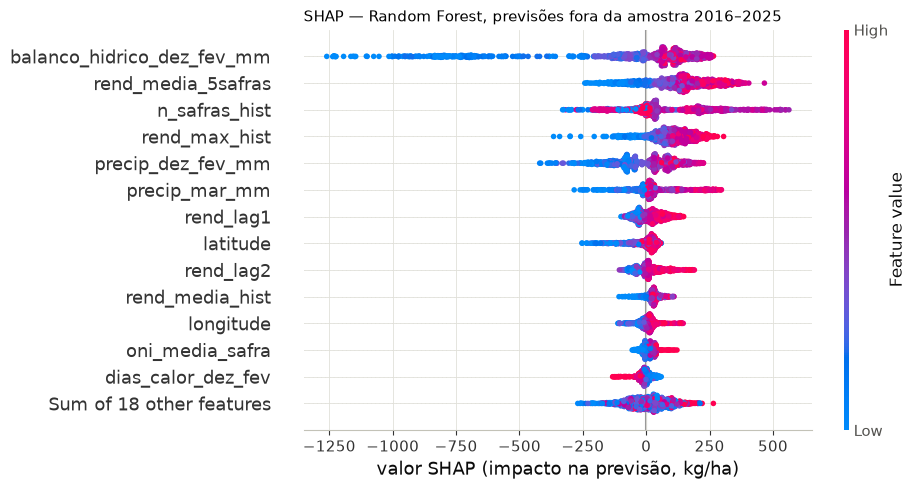

In [21]:
manter = [i for i, n in enumerate(nomes) if not n.startswith("missingindicator")]
sv_plot = shap.Explanation(values=vals[:, manter], data=dados[:, manter], feature_names=[nomes[i] for i in manter])
plt.figure()
shap.plots.beeswarm(sv_plot, max_display=14, show=False, plot_size=(8.2, 5.2))
plt.title(f"SHAP — {MELHOR}, previsões fora da amostra 2016–2025", loc="left", fontsize=10.5)
plt.xlabel("valor SHAP (impacto na previsão, kg/ha)")
plt.savefig(FIGDIR / "fig7_shap_resumo.png", bbox_inches="tight"); plt.show()

In [22]:
grupo_de = {**{a: "Histórico produtivo" for a in sp.ATR_HIST}, **{a: "Adubação" for a in sp.ATR_ADUBACAO},
            **{a: "ONI" for a in sp.ATR_ONI_PRE + sp.ATR_ONI_SAFRA}, **{a: "Clima INMET" for a in sp.ATR_CLIMA}}
por_grupo = imp.rename(lambda n: grupo_de.get(n.replace("missingindicator_", ""), "outros")).groupby(level=0).sum()
print((por_grupo / por_grupo.sum() * 100).sort_values(ascending=False).round(1).to_string())

Histórico produtivo    49.9
Clima INMET            43.1
Adubação                4.5
ONI                     2.5


### 10.1 Explicação local: um município na seca de 2022

Exemplo de como o artefato pode justificar uma previsão individual (útil para auditoria humana).

       municipio  rendimento_kg_ha  rend_media_hist
Dom Pedrito - RS            1700.0      1862.090909 | previsto: 2029


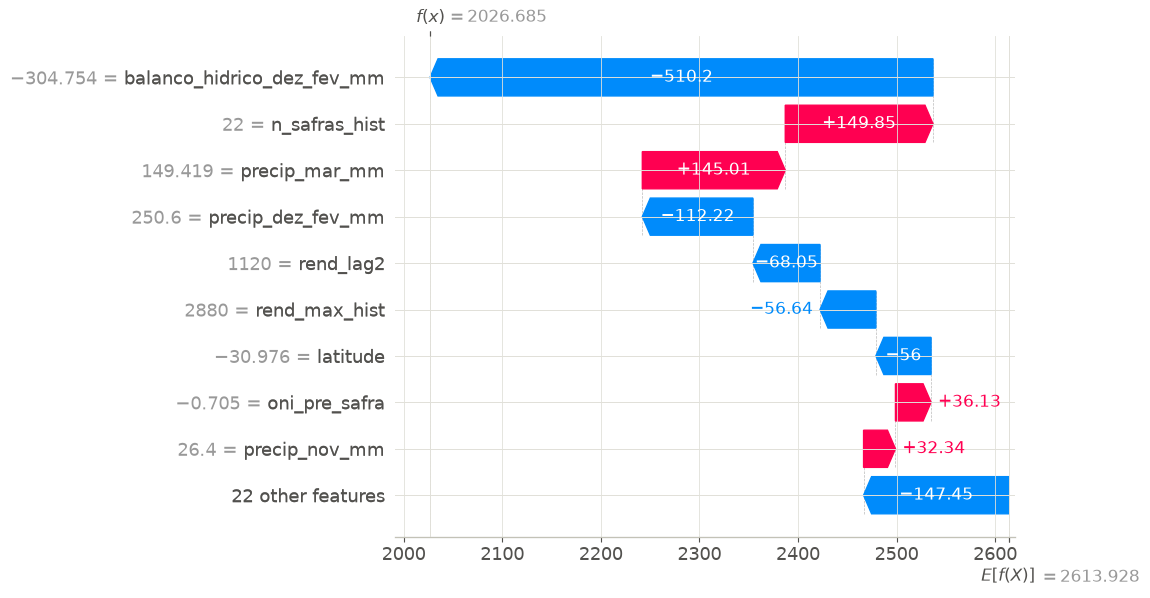

In [23]:
t = 2022
mdl = modelos_teste["B_fim_safra"][(t, MELHOR)]
b22 = base[base.ano_safra == t]
idx = b22.area_plantada_ha.idxmax()          # maior área plantada do RS em 2022
linha = b22.loc[[idx]]
local = sp.shap_valores(mdl, linha[atrB])
print(linha[["municipio", "rendimento_kg_ha", "rend_media_hist"]].to_string(index=False),
      "| previsto:", round(float(mdl.predict(linha[atrB])[0])))
manter_l = [i for i, n in enumerate(local.feature_names) if not n.startswith("missingindicator")]
plt.figure()
shap.plots.waterfall(shap.Explanation(values=local.values[0, manter_l], base_values=local.base_values[0],
                                      data=local.data[0, manter_l],
                                      feature_names=[local.feature_names[i] for i in manter_l]),
                     max_display=10, show=False)
plt.show()

## 11. Artefato: previsão de uma safra e ranking de risco

`src/prever_safra.py` encapsula o uso do modelo: treina com todas as safras anteriores à safra alvo e devolve, por município, a previsão, a referência histórica, o desvio percentual e o alerta de quebra. Pela linha de comando:

```bash
python src/prever_safra.py --safra 2025 --cenario B_fim_safra --modelo "Random Forest"
```

Abaixo, a mesma chamada feita a partir do notebook (safra 2025, cujos valores oficiais já foram divulgados e permitem conferir).

In [24]:
ranking, _ = sp.prever_safra(df, 2025, "B_fim_safra", MELHOR, PARAMS)
ranking.to_csv(RESDIR / "previsao_safra_2025.csv", index=False)
print("Municípios com alerta de quebra:", int(ranking.alerta_quebra.sum()), "de", len(ranking))
obs = ranking["observado_kg_ha (se já divulgado)"]
print("Desses, com quebra observada:", int((ranking.alerta_quebra & (obs < .8 * ranking.rend_media_hist)).sum()))
ranking.head(12).round(0)

Municípios com alerta de quebra: 41 de 414
Desses, com quebra observada: 27


,codigo_ibge_municipio,municipio,ano_safra,rend_media_hist,observado_kg_ha (se já divulgado),previsto_kg_ha,desvio_vs_media_hist_pct,alerta_quebra
0,4313037,Nova Esperança do Sul - RS,2025,2363.0,1500.0,766.0,-68.0,True
1,4304655,Capão do Cipó - RS,2025,2032.0,1782.0,717.0,-65.0,True
2,4319158,São Miguel das Missões - RS,2025,2068.0,1734.0,745.0,-64.0,True
3,4318903,São Luiz Gonzaga - RS,2025,2048.0,1539.0,765.0,-63.0,True
4,4302501,Bossoroca - RS,2025,1757.0,908.0,658.0,-63.0,True
5,4322376,Unistalda - RS,2025,1895.0,1260.0,722.0,-62.0,True
6,4317400,Santiago - RS,2025,2040.0,1347.0,786.0,-61.0,True
7,4310553,Itacurubi - RS,2025,1694.0,1379.0,711.0,-58.0,True
8,4307815,Estrela Velha - RS,2025,2457.0,1800.0,1591.0,-35.0,True
9,4302238,Boa Vista do Incra - RS,2025,2461.0,2481.0,1648.0,-33.0,True


## 12. Conclusões da modelagem

Os números citados abaixo são os impressos nas células anteriores (e salvos em `resultados/`).

- No **cenário B** (fim da safra, com clima observado) os três modelos superam as três baselines no agregado do teste 2016–2025: frente à melhor baseline (média das 5 últimas safras, MAE ≈ 696 kg/ha), o Gradient Boosting reduz o MAE em ≈ 19%, o Random Forest (selecionado na validação) em ≈ 17% e a Regressão Linear em ≈ 12%; os modelos de árvores vencem essa baseline em 7 de 10 safras.
- No **cenário A** (semeadura: histórico + adubação + ONI pré-safra) **nenhum** modelo supera a baseline: o ONI sozinho não antecipa as quebras do período de teste.
- A ablação mostra que o ganho vem dos **atributos climáticos do período crítico** (MAE ≈ 760 → ≈ 570). A **adubação fosfatada**, construída a partir de recomendações normativas, não altera o erro — resultado esperado por construção. O SHAP ainda lhe atribui ≈ 4–5% da importância, porque divide o crédito entre atributos colineares (a dose é função da média histórica): **atribuição SHAP não é efeito causal**.
- Os maiores erros estão nas **secas sem precedente** (2020, 2022), cuja magnitude é subestimada (regressão à média; Tmax dez–fev de 2022 acima de todo o treino). Como alerta de quebra, o modelo é conservador: precisão ≈ 0,6 e revocação ≈ 0,17 no limiar de 80%, ajustável pelo gestor (revocação ≈ 0,45 com limiar 105%).
- O SHAP é agronomicamente coerente — balanço hídrico e chuva de dez–fev baixos e mais dias de calor reduzem a previsão; o histórico do município define o patamar — e foi usado para **depurar** o modelo (remoção de `ano_safra`).
- O erro é menor no Norte (principal região produtora) e o ganho sobre a baseline é pequeno no Sul, onde há menos histórico de soja — limitação de equidade discutida no artigo.